PRÉ-PROCESSAMENTO

Ana Julia Ferreira Rodrigues e Guilherme Laurindo de Souza Silva — 5º DSM

1. Importação das bibliotecas e carregamento dos dados

Nesta etapa são importadas as bibliotecas utilizadas durante o pré-processamento e o conjunto de dados é carregado.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

df = pd.read_csv("dataset.csv")

print("Número de registros:", df.shape[0])
print("Número de atributos:", df.shape[1])

display(df.head())

Número de registros: 4424
Número de atributos: 35


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


Teste

In [2]:
print("Dimensão do dataset:", df.shape)
print("\nPrimeiras linhas:")
display(df.head())

Dimensão do dataset: (4424, 35)

Primeiras linhas:


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


2. Informações sobre os atributos

Nesta etapa verificamos os tipos de dados e a quantidade de registros preenchidos em cada coluna.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupation                      

Teste

In [4]:
print("Quantidade de colunas:", len(df.columns))
print("\nTipos de dados:")
display(df.dtypes.value_counts())

Quantidade de colunas: 35

Tipos de dados:


,count
int64,29
float64,5
object,1


O conjunto possui 35 colunas, sendo 34 atributos utilizados como características dos estudantes e a variável Target, que representa a situação acadêmica a ser prevista.

3. Estatísticas descritivas

Nesta etapa são analisadas algumas estatísticas dos atributos numéricos, como média, desvio padrão, valores mínimo e máximo e quartis.

In [5]:
display(df.describe())

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,6.886980,1.727848,9.899186,0.890823,2.531420,1.254521,12.322107,16.455244,7.317812,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,5.298964,1.313793,4.331792,0.311897,3.963707,1.748447,9.026251,11.044800,3.997828,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,6.000000,1.000000,1.000000,1.000000,2.000000,3.000000,5.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,8.000000,1.000000,10.000000,1.000000,1.000000,1.000000,13.000000,14.000000,6.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,12.000000,2.000000,13.000000,1.000000,1.000000,1.000000,22.000000,27.000000,10.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,18.000000,9.000000,17.000000,1.000000,17.000000,21.000000,29.000000,34.000000,32.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


Teste

In [6]:
print("Estatísticas descritivas calculadas com sucesso.")
print("Quantidade de atributos numéricos:",
      len(df.select_dtypes(include=np.number).columns))

Estatísticas descritivas calculadas com sucesso.
Quantidade de atributos numéricos: 34


Essa análise permite observar a distribuição geral dos valores e identificar possíveis valores muito diferentes dos demais.

4. Verificação de valores ausentes

A professora realiza uma etapa específica para verificar valores ausentes.

In [ ]:
print("Valores ausentes por coluna:")
display(df.isnull().sum())

Teste

In [7]:
total_nulos = df.isnull().sum().sum()

print("Total de valores ausentes:", total_nulos)

if total_nulos == 0:
    print("Teste OK: não existem valores ausentes.")
else:
    print("Existem valores ausentes que precisam ser tratados.")

Total de valores ausentes: 0
Teste OK: não existem valores ausentes.


Portanto, não foi necessário realizar preenchimento ou exclusão de registros por valores ausentes.

5. Verificação de registros duplicados

A professora também verifica registros duplicados antes de realizar o tratamento.

In [8]:
duplicados = df.duplicated().sum()

print("Total de registros duplicados:", duplicados)

Total de registros duplicados: 0


Teste

In [9]:
if duplicados == 0:
    print("Teste OK: não existem registros completamente duplicados.")
else:
    print("Foram encontrados registros duplicados.")

Teste OK: não existem registros completamente duplicados.


Tratamento

Caso existam registros duplicados, eles serão removidos.

In [11]:
if duplicados > 0:
    df = df.drop_duplicates()
    print("Duplicados removidos.")
else:
    print("Nenhum registro foi removido.")

Nenhum registro foi removido.


Teste após o tratamento

In [12]:
print("Duplicados após o tratamento:", df.duplicated().sum())
print("Dimensão atual do dataset:", df.shape)

Duplicados após o tratamento: 0
Dimensão atual do dataset: (4424, 35)


No nosso conjunto de dados foram encontrados 0 registros duplicados, portanto nenhum registro precisou ser removido.

6. Verificação de inconsistências

Nesta etapa verificamos os valores existentes na variável que representa a classe.

In [13]:
print("Valores existentes na variável Target:")
display(df["Target"].unique())

Valores existentes na variável Target:


array(['Dropout', 'Graduate', 'Enrolled'], dtype=object)

Teste

In [14]:
print("Quantidade de classes:", df["Target"].nunique())

print("\nQuantidade de registros por classe:")
display(df["Target"].value_counts())

Quantidade de classes: 3

Quantidade de registros por classe:


,count
Target,
Graduate,2209
Dropout,1421
Enrolled,794


Gráfico

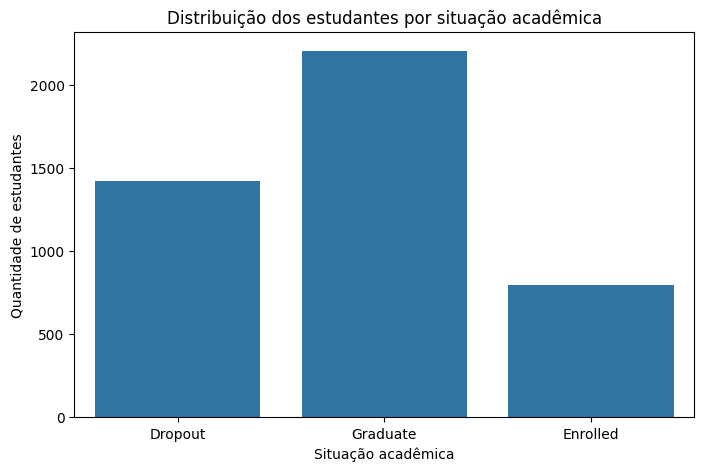

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(x="Target", data=df)

plt.title("Distribuição dos estudantes por situação acadêmica")
plt.xlabel("Situação acadêmica")
plt.ylabel("Quantidade de estudantes")

plt.show()

Teste

In [16]:
distribuicao = df["Target"].value_counts()

print("Classe com maior quantidade de registros:",
      distribuicao.idxmax())

print("Classe com menor quantidade de registros:",
      distribuicao.idxmin())

Classe com maior quantidade de registros: Graduate
Classe com menor quantidade de registros: Enrolled


No conjunto original, a distribuição encontrada foi:

Graduate    2209

Dropout     1421

Enrolled     794


8. Análise de possíveis outliers

A professora utiliza boxplots para identificar possíveis valores discrepantes.

Como nosso dataset possui muitas variáveis codificadas numericamente, a análise será realizada apenas sobre as variáveis numéricas.

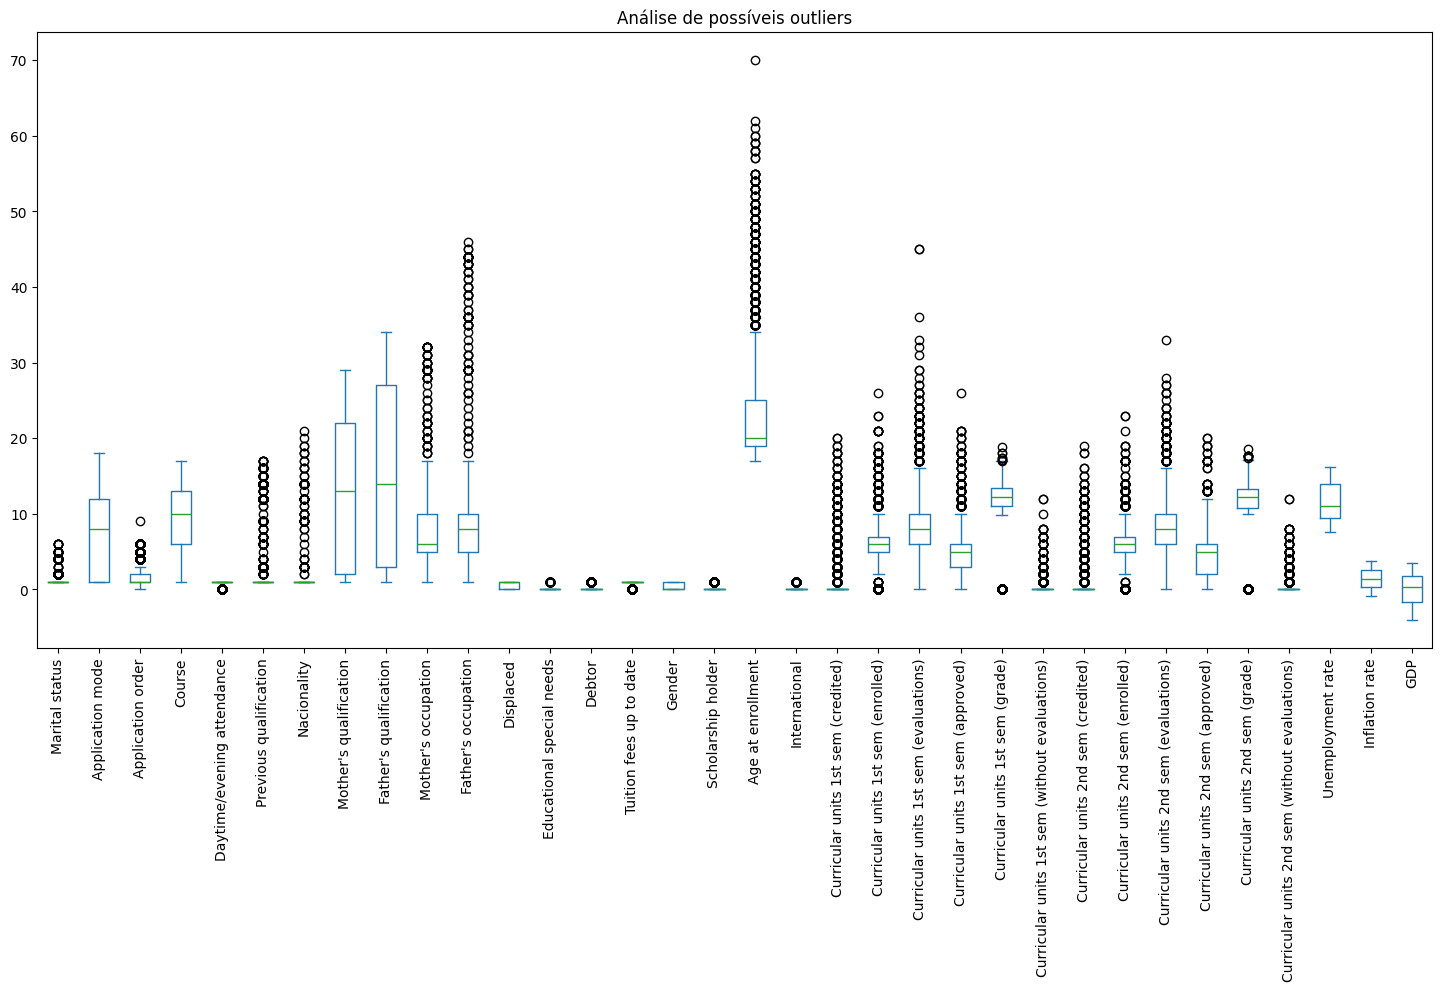

In [17]:
colunas_numericas = df.select_dtypes(include=np.number).columns

df[colunas_numericas].plot(
    kind="box",
    figsize=(18, 8)
)

plt.xticks(rotation=90)
plt.title("Análise de possíveis outliers")
plt.show()

Teste pelo método IQR

In [18]:


def contar_outliers(df, coluna):
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ]

    return len(outliers)


resultado_outliers = {}

for coluna in colunas_numericas:
    resultado_outliers[coluna] = contar_outliers(df, coluna)

outliers_df = pd.DataFrame(
    list(resultado_outliers.items()),
    columns=["Atributo", "Quantidade de possíveis outliers"]
)

display(
    outliers_df.sort_values(
        by="Quantidade de possíveis outliers",
        ascending=False
    )
)

,Atributo,Quantidade de possíveis outliers
16,Scholarship holder,1099
29,Curricular units 2nd sem (grade),877
23,Curricular units 1st sem (grade),726
5,Previous qualification,707
19,Curricular units 1st sem (credited),577
2,Application order,541
25,Curricular units 2nd sem (credited),530
14,Tuition fees up to date,528
0,Marital status,505
13,Debtor,503


Nesta etapa os valores são identificados, mas não são removidos automaticamente.

Isso ocorre porque o método IQR pode identificar como outlier um valor que, apesar de extremo, ainda seja válido para o contexto acadêmico.

Portanto, a análise dos outliers é realizada antes de qualquer decisão de remoção.

9. Correlação entre os atributos

A professora também realiza uma análise de correlação entre os atributos.

Primeiro selecionamos apenas os atributos numéricos.

In [19]:
df_numerico = df.select_dtypes(include=np.number)

Matriz de correlação

In [20]:
correlacao = df_numerico.corr()

display(correlacao)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
Marital status,1.000000,0.224855,-0.125854,0.018925,-0.274939,0.120925,-0.020722,0.185522,0.128326,0.069734,...,0.034711,0.062831,0.039026,0.022784,-0.043739,-0.071506,0.020426,-0.020338,0.008761,-0.027003
Application mode,0.224855,1.000000,-0.246497,-0.085116,-0.268616,0.433028,-0.001360,0.092867,0.072798,0.033489,...,0.040255,0.228973,0.127461,0.164992,-0.065203,-0.104424,0.042009,0.091567,-0.019613,-0.014563
Application order,-0.125854,-0.246497,1.000000,0.118928,0.158657,-0.199029,-0.029385,-0.061719,-0.049936,-0.046591,...,-0.031699,-0.125815,0.028878,-0.055089,0.071793,0.055517,-0.015757,-0.098419,-0.011133,0.030201
Course,0.018925,-0.085116,0.118928,1.000000,-0.070232,-0.158382,-0.004761,0.058909,0.045659,0.029672,...,-0.060483,-0.120390,0.185879,0.049236,0.120000,0.178997,-0.013984,-0.050116,0.028775,-0.012518
Daytime/evening attendance,-0.274939,-0.268616,0.158657,-0.070232,1.000000,-0.103022,0.024433,-0.195346,-0.137769,-0.037986,...,0.045630,-0.111953,0.000371,0.014610,0.034022,0.050493,-0.004229,0.061974,-0.024043,0.022929
Previous qualification,0.120925,0.433028,-0.199029,-0.158382,-0.103022,1.000000,-0.038997,0.018868,0.013152,0.006190,...,0.018276,0.138463,0.056450,0.101501,-0.037265,-0.038765,0.024186,0.096914,-0.056388,0.053968
Nacionality,-0.020722,-0.001360,-0.029385,-0.004761,0.024433,-0.038997,1.000000,-0.043847,-0.088892,0.044123,...,0.026203,-0.000747,-0.020103,-0.018023,-0.014142,-0.005409,-0.012052,-0.006013,-0.012331,0.044563
Mother's qualification,0.185522,0.092867,-0.061719,0.058909,-0.195346,0.018868,-0.043847,1.000000,0.524529,0.295178,...,0.003293,0.036986,0.033070,0.018874,-0.013161,-0.028472,0.020364,-0.106107,0.056653,-0.079664
Father's qualification,0.128326,0.072798,-0.049936,0.045659,-0.137769,0.013152,-0.088892,0.524529,1.000000,0.207067,...,-0.017785,0.041695,0.023635,0.009471,0.006052,-0.006508,-0.008493,-0.075417,0.056661,-0.070200
Mother's occupation,0.069734,0.033489,-0.046591,0.029672,-0.037986,0.006190,0.044123,0.295178,0.207067,1.000000,...,-0.012569,-0.002057,0.009287,0.011546,0.022309,0.035230,-0.004903,-0.011772,0.015014,0.091880


Heatmap

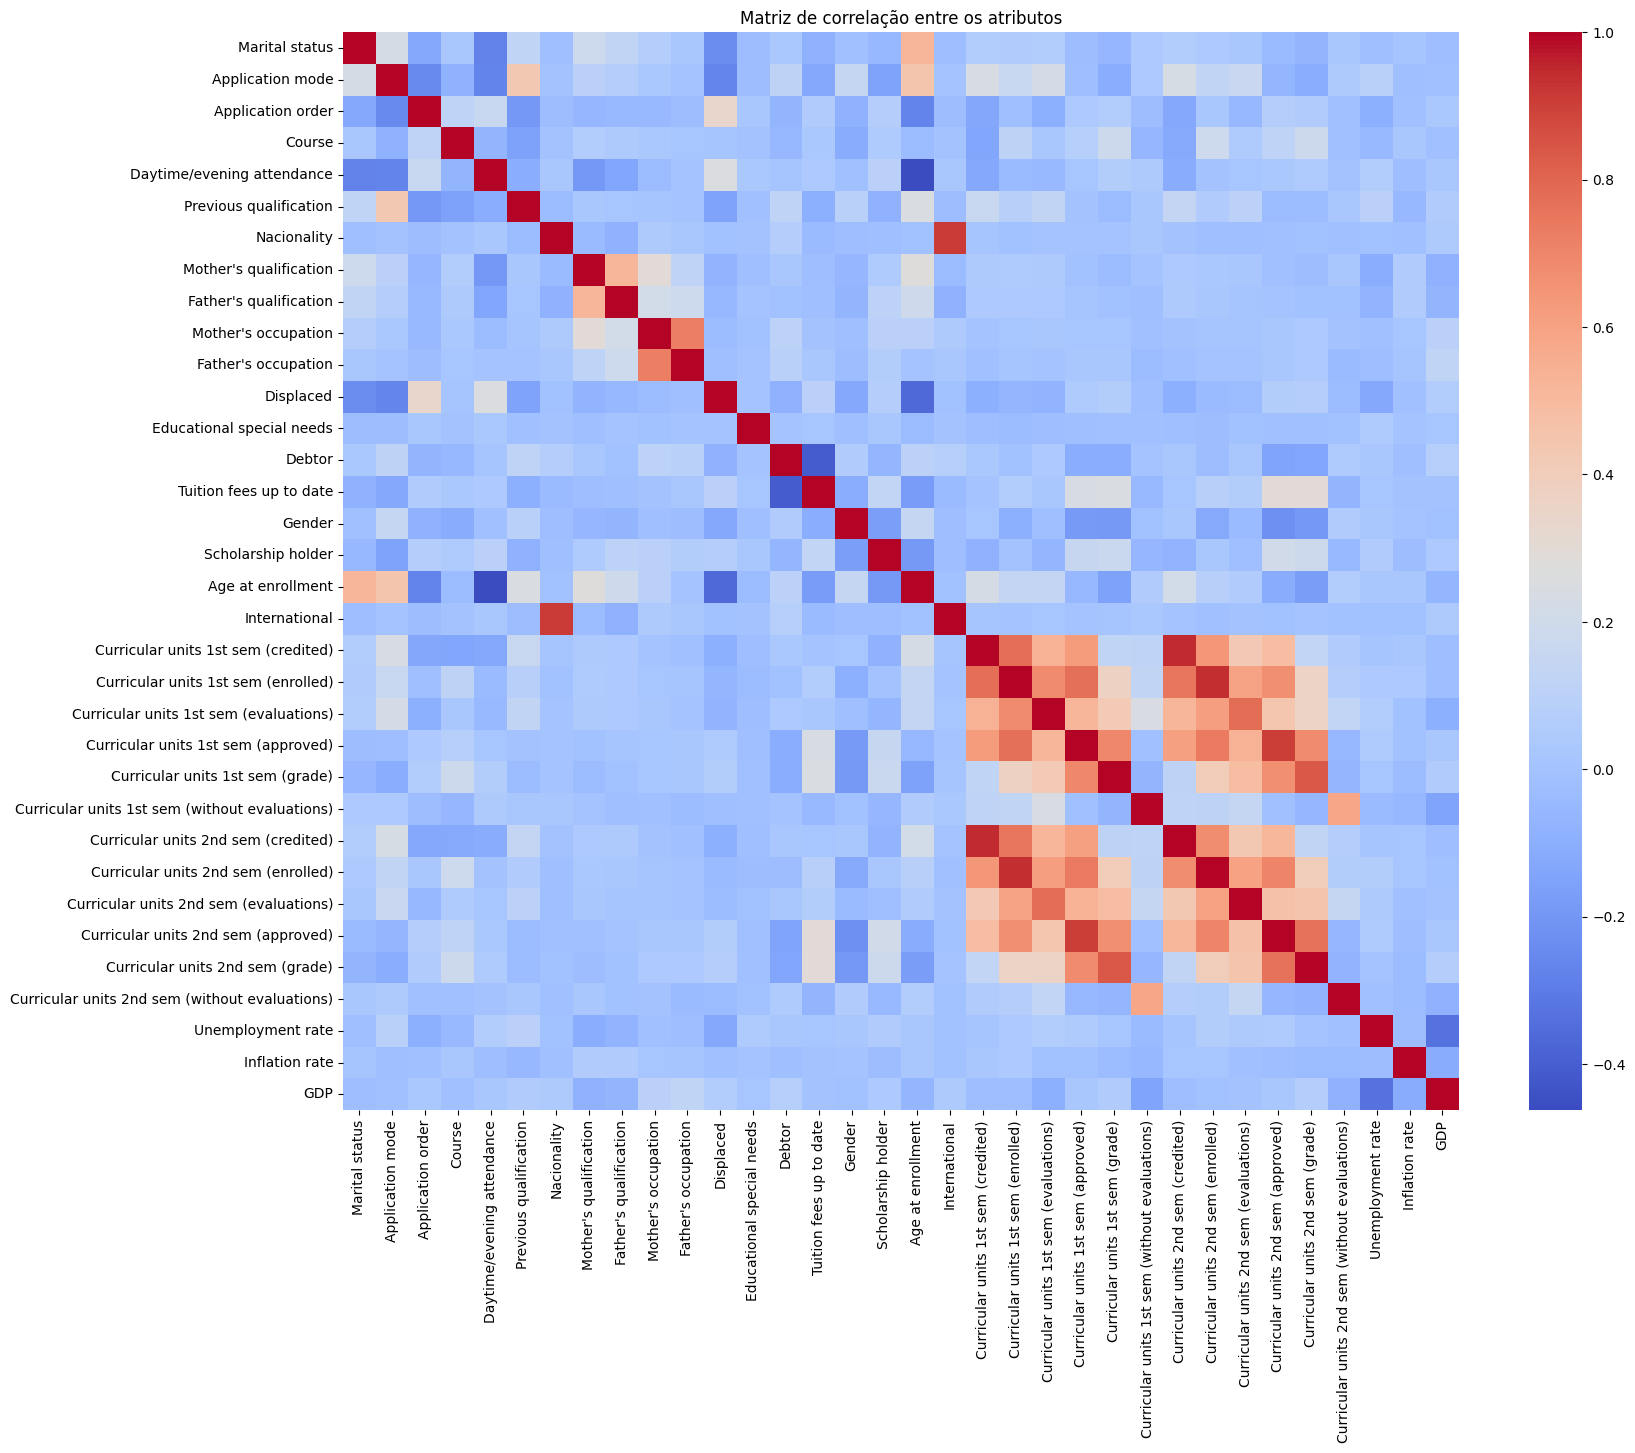

In [21]:
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlacao,
    annot=False,
    cmap="coolwarm"
)

plt.title("Matriz de correlação entre os atributos")
plt.show()

Teste

In [22]:
print("Matriz de correlação criada.")
print("Quantidade de atributos analisados:",
      len(df_numerico.columns))

Matriz de correlação criada.
Quantidade de atributos analisados: 34


Essa análise permite identificar atributos que apresentam maior ou menor relação linear entre si.

10. Separação entre atributos e variável alvo

Após as análises iniciais, separamos os atributos utilizados para realizar a previsão da variável que representa o resultado.

In [23]:
X = df.drop("Target", axis=1)
y = df["Target"]

Teste

In [24]:
print("Dimensão de X:", X.shape)
print("Dimensão de y:", y.shape)

Dimensão de X: (4424, 34)
Dimensão de y: (4424,)


Ou seja:

X possui 34 atributos;

y possui a classe que queremos prever.

11. Separação dos dados em treinamento e teste

Os dados são divididos em 80% para treinamento e 20% para teste.

A opção stratify=y é utilizada para manter uma distribuição semelhante das três classes nos dois conjuntos.

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Teste

In [26]:
print("Dados de treinamento:", X_train.shape)
print("Dados de teste:", X_test.shape)

print("\nDistribuição das classes no treinamento:")
display(y_train.value_counts())

print("\nDistribuição das classes no teste:")
display(y_test.value_counts())

Dados de treinamento: (3539, 34)
Dados de teste: (885, 34)

Distribuição das classes no treinamento:


,count
Target,
Graduate,1767
Dropout,1137
Enrolled,635



Distribuição das classes no teste:


,count
Target,
Graduate,442
Dropout,284
Enrolled,159


12. Identificação das variáveis categóricas

Apesar de várias colunas estarem armazenadas como números, algumas representam categorias ou códigos de categorias.

Essas variáveis serão transformadas utilizando One-Hot Encoding.

In [27]:
categorical_features = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

As demais variáveis serão tratadas como numéricas.

In [28]:
numeric_features = [
    coluna for coluna in X.columns
    if coluna not in categorical_features
]

print("Variáveis categóricas:", len(categorical_features))
print("Variáveis numéricas:", len(numeric_features))

Variáveis categóricas: 17
Variáveis numéricas: 17


13. One-Hot Encoding e padronização

As variáveis categóricas serão transformadas utilizando OneHotEncoder.

As variáveis numéricas serão padronizadas utilizando StandardScaler.

In [29]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

14. Aplicação do pré-processamento

O pré-processamento é ajustado somente com os dados de treinamento.

In [30]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

Teste

In [31]:
print("Formato original do treinamento:", X_train.shape)
print("Formato após o pré-processamento:", X_train_processed.shape)

print("\nFormato original do teste:", X_test.shape)
print("Formato após o pré-processamento:", X_test_processed.shape)

Formato original do treinamento: (3539, 34)
Formato após o pré-processamento: (3539, 242)

Formato original do teste: (885, 34)
Formato após o pré-processamento: (885, 242)


No nosso pré-processamento, os 34 atributos originais são transformados em 242 atributos após a codificação e padronização.

15. Codificação da variável Target

A variável Target possui três classes textuais:

Dropout

Enrolled

Graduate

Para utilização no modelo, essas classes serão transformadas em valores numéricos.

In [32]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

Teste

In [33]:
print("Classes originais:")
print(label_encoder.classes_)

print("\nPrimeiros valores codificados:")
print(y_train_encoded[:10])

Classes originais:
['Dropout' 'Enrolled' 'Graduate']

Primeiros valores codificados:
[2 0 1 2 2 1 0 0 0 0]


16. Verificação final do pré-processamento

Nesta etapa verificamos se os dados estão prontos para serem utilizados pelo modelo.

In [34]:
print("========== VERIFICAÇÃO FINAL ==========")

print("Registros de treinamento:", X_train_processed.shape[0])
print("Atributos após processamento:", X_train_processed.shape[1])

print("Registros de teste:", X_test_processed.shape[0])
print("Atributos após processamento:", X_test_processed.shape[1])

print("Quantidade de classes:", len(label_encoder.classes_))

print("\nClasses:")
print(label_encoder.classes_)

========== VERIFICAÇÃO FINAL ==========
Registros de treinamento: 3539
Atributos após processamento: 242
Registros de teste: 885
Atributos após processamento: 242
Quantidade de classes: 3

Classes:
['Dropout' 'Enrolled' 'Graduate']


Teste final

In [35]:
print("\n========== TESTES ==========")

print(
    "1. Valores ausentes:",
    df.isnull().sum().sum()
)

print(
    "2. Registros duplicados:",
    df.duplicated().sum()
)

print(
    "3. Classes encontradas:",
    list(label_encoder.classes_)
)

print(
    "4. Dados de treinamento processados:",
    X_train_processed.shape
)

print(
    "5. Dados de teste processados:",
    X_test_processed.shape
)


========== TESTES ==========
1. Valores ausentes: 0
2. Registros duplicados: 0
3. Classes encontradas: ['Dropout', 'Enrolled', 'Graduate']
4. Dados de treinamento processados: (3539, 242)
5. Dados de teste processados: (885, 242)


Conclusão do pré-processamento

O conjunto de dados utilizado possui 4.424 registros e 35 atributos, sendo 34 características dos estudantes e uma variável alvo denominada Target.

Inicialmente foram realizadas verificações de estrutura, valores ausentes, registros duplicados, distribuição das classes, possíveis outliers e correlação entre os atributos.

Não foram encontrados valores ausentes nem registros completamente duplicados. A variável Target apresenta três classes: Dropout, Enrolled e Graduate.

Na etapa de preparação para o modelo, os dados foram separados em treinamento e teste, utilizando 80% dos registros para treinamento e 20% para teste. As variáveis categóricas foram transformadas utilizando One-Hot Encoding e as variáveis numéricas foram padronizadas utilizando StandardScaler.

Ao final do processo, os dados estavam preparados para serem utilizados no modelo de aprendizado de máquina, mantendo a separação adequada entre os dados de treinamento e teste.